# BusView — Previsão de lotação de ônibus com dado real

**Global Solution 2026.2 · Data Science & Statistical Computing**
**Equipe:** Frota 42
**Integrantes:** Felipe Balbino Murad (RM562347) · Lucas Mesquita Massoni (RM561686)

---

## O problema

O passageiro não tem como saber, antes de sair de casa, se o ônibus que vai pegar estará lotado. Ele descobre apenas quando o veículo chega ao ponto — e, nesse momento, a decisão já foi tomada.

## O cidadão beneficiado

O passageiro de ônibus urbano que usa o transporte como deslocamento obrigatório para trabalho, estudo ou atendimento de saúde, e que depende do aplicativo para decidir se sai agora ou espera a próxima partida.

## Perguntas de pesquisa

Duas perguntas orientam o trabalho:

1. É possível prever a ocupação de um ônibus cinco paradas à frente, usando apenas informações disponíveis antes de ele chegar — trajeto, horário, linha e a leitura de passageiros a bordo feita no ponto atual?
2. A leitura de contagem a bordo (câmera no veículo) reduz o erro a ponto de justificar o investimento, ou o resultado é explicado apenas pelo trajeto e pelo horário?

## Variáveis-alvo

**Alvo numérico, para regressão linear:** `saldo_futuro` — quantidade de passageiros a bordo cinco paradas à frente, na mesma viagem.

**Alvo binário, para regressão logística:** `lotado_futuro` — vale 1 quando `saldo_futuro` é maior ou igual a 40 passageiros.

O limiar de 40 é decisão de produto, não valor estatístico ótimo: corresponde à ocupação de todos os assentos de um veículo convencional, ponto a partir do qual o passageiro viaja em pé. Na base, esse limiar resulta em prevalência de 12,1%.

## Hipóteses

**H1.** O padrão de ocupação é previsível a partir de variáveis mecânicas do trajeto e do tempo, sem nenhum sensor a bordo. *Teste:* modelo sem a variável de contagem atual, comparado ao baseline de média histórica por linha e horário.

**H2.** A leitura de ocupação feita a bordo reduz o erro de previsão de forma mensurável. *Teste:* dois modelos idênticos, variando apenas a presença da variável `ocup_atual`.

## Fonte dos dados

Dados públicos reais da BHTRANS (Empresa de Transporte e Trânsito de Belo Horizonte), publicados pela Prefeitura de Belo Horizonte no Portal de Dados Abertos, licenciados em Creative Commons Attribution.

Dataset: *Dados das pesquisas de embarque e desembarque de passageiros do transporte coletivo*.
Arquivo: `movimentacao_sobe_desce_29-11-2018-001.csv` — 180.406 registros, 3.156 viagens, 157 linhas, 160 datas entre novembro de 2008 e março de 2018.

A base não contém dados pessoais: são contagens agregadas por ponto de parada e por viagem. Detalhes completos em `FONTE_DADOS.txt`.

## Estrutura do notebook

**0.** Contexto, perguntas, variáveis-alvo e hipóteses (esta célula)
**1.** Carregamento e inspeção inicial da base real
**2.** Limpeza, identificação de viagem e diagnóstico de integridade
**3.** Construção dos alvos, definição do limiar e split treino/teste sem vazamento
**4.** Regressão linear: baseline, modelo sem câmera e modelo com câmera
**5.** Regressão logística: classificação de lotação e escolha do threshold
**6.** Visualizações
**7.** Indicador de impacto ao nível de viagem
**8.** Recomendações, limitações e conclusão

In [1]:
# CELULA 1C - Upload manual da base real
# Fonte: BHTRANS / Prefeitura de Belo Horizonte
# Dataset: Dados das pesquisas de embarque e desembarque de passageiros
#          do transporte coletivo - Parte 1
# Licenca: Creative Commons Attribution

from google.colab import files
import pandas as pd, io

enviado = files.upload()
nome = list(enviado.keys())[0]
print("Arquivo recebido:", nome)
print("Tamanho:", round(len(enviado[nome]) / 1_000_000, 1), "MB")

df = None
for enc in ["utf-8", "latin-1", "cp1252"]:
    try:
        temp = pd.read_csv(io.BytesIO(enviado[nome]), sep=";",
                           encoding=enc, low_memory=False)
        if temp.shape[1] >= 10:
            df = temp
            print("Encoding usado:", enc)
            break
    except Exception as e:
        print("Falhou com", enc, "->", type(e).__name__)

if df is None:
    raise ValueError("Nenhum encoding funcionou.")

# normaliza nomes de coluna (o CSV traz espacos no inicio)
df.columns = [c.strip() for c in df.columns]

print("\n=== DIMENSOES ===")
print(df.shape)

print("\n=== COLUNAS ===")
print(list(df.columns))

print("\n=== TIPOS ===")
print(df.dtypes)

print("\n=== PRIMEIRAS 5 LINHAS ===")
display(df.head())

print("\n=== NULOS ===")
print(df.isna().sum())

print("\n=== CARDINALIDADE ===")
for c in df.columns:
    print(f"  {c}: {df[c].nunique()} distintos")

print("\n=== COBERTURA ===")
print("Linhas distintas:", df["Linha/SubLinha"].nunique())
print("Rotas distintas:", df["Rota"].nunique())
print("Datas de pesquisa distintas:", df["Data Pesquisa"].nunique())
print("Primeira data:", df["Data Pesquisa"].min())
print("Ultima data:", df["Data Pesquisa"].max())

print("\n=== VARIAVEL-ALVO: Saldo ===")
print(df["Saldo"].describe().round(2))

print("\n=== TOP 10 LINHAS POR REGISTROS ===")
print(df["Linha/SubLinha"].value_counts().head(10))

Saving movimentacao_sobe_desce_29-11-2018-001.csv to movimentacao_sobe_desce_29-11-2018-001.csv
Arquivo recebido: movimentacao_sobe_desce_29-11-2018-001.csv
Tamanho: 41.4 MB
Falhou com utf-8 -> UnicodeDecodeError
Encoding usado: latin-1

=== DIMENSOES ===
(180406, 15)

=== COLUNAS ===
['Linha/SubLinha', 'Servico', 'Consorcio', 'Data Pesquisa', 'Dia Semana', 'Rota', 'Hora Viagem', 'Sequencia do PED', 'Endereco do PED', 'Embarque', 'Desembarque', 'Saldo', 'Total Passageiros', 'Latitude', 'Longitude']

=== TIPOS ===
Linha/SubLinha       object
Servico              object
Consorcio            object
Data Pesquisa        object
Dia Semana           object
Rota                 object
Hora Viagem          object
Sequencia do PED      int64
Endereco do PED      object
Embarque              int64
Desembarque           int64
Saldo                 int64
Total Passageiros     int64
Latitude             object
Longitude            object
dtype: object

=== PRIMEIRAS 5 LINHAS ===


,Linha/SubLinha,Servico,Consorcio,Data Pesquisa,Dia Semana,Rota,Hora Viagem,Sequencia do PED,Endereco do PED,Embarque,Desembarque,Saldo,Total Passageiros,Latitude,Longitude
0,SC01A/01,CIRCULAR,CONSORCIO PAMPULHA,10/11/2012,Sabado,Pc1->Pc2,07:31,1,AVE DO CONTORNO 9716 ...,4,0,4,99,"-19,921336","-43,957061"
1,SC01A/01,CIRCULAR,CONSORCIO PAMPULHA,10/11/2012,Sabado,Pc1->Pc2,07:31,2,AVE DO CONTORNO 10080 ...,0,0,4,99,"-19,918387","-43,955523"
2,SC01A/01,CIRCULAR,CONSORCIO PAMPULHA,10/11/2012,Sabado,Pc1->Pc2,07:31,3,AVE DO CONTORNO 10424 ...,6,0,10,99,"-19,917667","-43,952557"
3,SC01A/01,CIRCULAR,CONSORCIO PAMPULHA,10/11/2012,Sabado,Pc1->Pc2,07:31,4,AVE DO CONTORNO 10500 ...,6,0,16,99,"-19,91772","-43,95177"
4,SC01A/01,CIRCULAR,CONSORCIO PAMPULHA,10/11/2012,Sabado,Pc1->Pc2,07:31,5,AVE DO CONTORNO 10706 ...,8,0,24,99,"-19,917871","-43,949958"



=== NULOS ===
Linha/SubLinha       0
Servico              0
Consorcio            0
Data Pesquisa        0
Dia Semana           0
Rota                 0
Hora Viagem          0
Sequencia do PED     0
Endereco do PED      0
Embarque             0
Desembarque          0
Saldo                0
Total Passageiros    0
Latitude             0
Longitude            0
dtype: int64

=== CARDINALIDADE ===
  Linha/SubLinha: 157 distintos
  Servico: 11 distintos
  Consorcio: 4 distintos
  Data Pesquisa: 160 distintos
  Dia Semana: 7 distintos
  Rota: 3 distintos
  Hora Viagem: 714 distintos
  Sequencia do PED: 120 distintos
  Endereco do PED: 3804 distintos
  Embarque: 72 distintos
  Desembarque: 69 distintos
  Saldo: 110 distintos
  Total Passageiros: 155 distintos
  Latitude: 3763 distintos
  Longitude: 3728 distintos

=== COBERTURA ===
Linhas distintas: 157
Rotas distintas: 3
Datas de pesquisa distintas: 160
Primeira data: 01/04/2012
Ultima data: 31/10/2011

=== VARIAVEL-ALVO: Saldo ===
count    1

In [2]:
# CELULA 2 - Limpeza, identificacao de viagem e diagnostico de integridade

import pandas as pd
import numpy as np

# --- 1. normalizar nomes de colunas (remove espacos) ---
df.columns = [c.strip() for c in df.columns]
print("Colunas apos limpeza:")
print(list(df.columns))

# --- 2. tipos ---
df["Data Pesquisa"] = pd.to_datetime(df["Data Pesquisa"], format="%d/%m/%Y", errors="coerce")
df["Latitude"]  = pd.to_numeric(df["Latitude"].astype(str).str.replace(",", "."), errors="coerce")
df["Longitude"] = pd.to_numeric(df["Longitude"].astype(str).str.replace(",", "."), errors="coerce")

print("\nDatas invalidas:", df["Data Pesquisa"].isna().sum())
print("Periodo:", df["Data Pesquisa"].min().date(), "a", df["Data Pesquisa"].max().date())

# --- 3. identificador de viagem ---
df["viagem_id"] = (df["Linha/SubLinha"].astype(str) + "|" +
                   df["Rota"].astype(str) + "|" +
                   df["Data Pesquisa"].dt.strftime("%Y%m%d") + "|" +
                   df["Hora Viagem"].astype(str))

print("\n=== VIAGENS ===")
print("Viagens distintas:", df["viagem_id"].nunique())
print("Pontos por viagem:")
print(df.groupby("viagem_id").size().describe().round(1))

# --- 4. variavel-alvo: ocupacao ---
# Saldo = pessoas dentro do veiculo naquele ponto (ja vem calculado)
print("\n=== SALDO (ocupacao real) ===")
print(df["Saldo"].describe(percentiles=[.5, .9, .99]).round(2))
print("Saldo negativo:", (df["Saldo"] < 0).sum())
print("Saldo maximo:", df["Saldo"].max())

print("\n=== TOTAL PASSAGEIROS POR VIAGEM ===")
print(df["Total Passageiros"].describe().round(1))
print("Total constante dentro da mesma viagem?",
      df.groupby("viagem_id")["Total Passageiros"].nunique().max() == 1)

# --- 5. integridade: saldo == acumulado de embarque - desembarque ---
df = df.sort_values(["viagem_id", "Sequencia do PED"])
df["saldo_calc"] = (df.groupby("viagem_id")["Embarque"].cumsum()
                    - df.groupby("viagem_id")["Desembarque"].cumsum())
df["dif"] = df["Saldo"] - df["saldo_calc"]

print("\n=== INTEGRIDADE DO SALDO ===")
print("Registros em que Saldo != acumulado:", (df["dif"] != 0).sum())
print("Diferenca maxima:", df["dif"].abs().max())

# --- 6. o veiculo esvazia no fim da viagem? ---
final = df.groupby("viagem_id").tail(1)
print("\n=== FIM DE VIAGEM ===")
print("Viagens terminando com saldo 0:",
      (final["Saldo"] == 0).sum(), "de", len(final),
      f"({round((final['Saldo']==0).mean()*100,1)}%)")

# --- 7. distribuicao por linha e data ---
print("\n=== TOP 10 LINHAS POR VIAGENS ===")
print(df.groupby("Linha/SubLinha")["viagem_id"].nunique().sort_values(ascending=False).head(10))

print("\n=== VIAGENS POR DIA DA SEMANA ===")
print(df.groupby("Dia Semana")["viagem_id"].nunique().sort_values(ascending=False))

print("\n=== AMPLITUDE DE DATAS ===")
datas = df["Data Pesquisa"].dt.to_period("M").value_counts().sort_index()
print(datas)

print("\n=== ROTAS ===")
print(df["Rota"].value_counts())

Colunas apos limpeza:
['Linha/SubLinha', 'Servico', 'Consorcio', 'Data Pesquisa', 'Dia Semana', 'Rota', 'Hora Viagem', 'Sequencia do PED', 'Endereco do PED', 'Embarque', 'Desembarque', 'Saldo', 'Total Passageiros', 'Latitude', 'Longitude']

Datas invalidas: 0
Periodo: 2008-11-26 a 2018-03-17

=== VIAGENS ===
Viagens distintas: 3156
Pontos por viagem:
count    3156.0
mean       57.2
std        29.3
min         8.0
25%        34.0
50%        55.0
75%        75.0
max       240.0
dtype: float64

=== SALDO (ocupacao real) ===
count    180406.00
mean         19.49
std          15.98
min           0.00
50%          16.00
90%          41.00
99%          70.00
max         110.00
Name: Saldo, dtype: float64
Saldo negativo: 0
Saldo maximo: 110

=== TOTAL PASSAGEIROS POR VIAGEM ===
count    180406.0
mean         64.2
std          27.8
min           0.0
25%          44.0
50%          62.0
75%          83.0
max         202.0
Name: Total Passageiros, dtype: float64
Total constante dentro da mesma via

In [3]:
# CELULA 3 - Variaveis-alvo, limiar de lotacao e split sem vazamento

import pandas as pd
import numpy as np
from sklearn.model_selection import GroupShuffleSplit

# --- ordenacao canonica ---
df = df.sort_values(["viagem_id", "Sequencia do PED"]).reset_index(drop=True)

K = 5  # horizonte de previsao em paradas

# --- alvo numerico: saldo daqui a K paradas, na mesma viagem ---
df["saldo_futuro"] = df.groupby("viagem_id")["Saldo"].shift(-K)

# --- posicao no trajeto ---
df["total_pontos"] = df.groupby("viagem_id")["Sequencia do PED"].transform("max")
df["posicao_relativa"] = df["Sequencia do PED"] / df["total_pontos"]
df["posicao_relativa_2"] = df["posicao_relativa"] ** 2
df["paradas_restantes"] = df["total_pontos"] - df["Sequencia do PED"]

# --- tempo ---
df["hora"] = pd.to_datetime(df["Hora Viagem"], format="%H:%M", errors="coerce").dt.hour
df["dia_semana_num"] = df["Data Pesquisa"].dt.dayofweek
df["ano"] = df["Data Pesquisa"].dt.year

# --- leitura da camera = Saldo do ponto atual ---
df["ocup_atual"] = df["Saldo"]

# --- manter apenas registros que tem alvo futuro ---
base = df[df["saldo_futuro"].notna()].copy()
print("Registros com alvo definido:", len(base), "de", len(df))

print("\n=== ALVO NUMERICO: passageiros a bordo em k+5 ===")
print(base["saldo_futuro"].describe(percentiles=[.5, .75, .9, .95]).round(2))

print("\n=== PREVALENCIA POR LIMIAR ===")
for lim in [30, 35, 40, 45, 50]:
    n = int((base["saldo_futuro"] >= lim).sum())
    print(f"  lotado = saldo_futuro >= {lim}: {n:>6} registros ({n/len(base)*100:.1f}%)")

# --- limiar adotado: 40 (todos os assentos ocupados) ---
LIMIAR = 40
base["lotado_futuro"] = (base["saldo_futuro"] >= LIMIAR).astype(int)
print(f"\nLimiar adotado: {LIMIAR} passageiros a bordo")
print("Prevalencia:", round(base["lotado_futuro"].mean() * 100, 1), "%")

# --- split agrupado por viagem ---
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
idx_tr, idx_te = next(gss.split(base, groups=base["viagem_id"]))

treino = base.iloc[idx_tr].copy()
teste  = base.iloc[idx_te].copy()

print("\n=== SPLIT POR VIAGEM ===")
print("Treino:", len(treino), "registros |",
      treino["viagem_id"].nunique(), "viagens")
print("Teste: ", len(teste), "registros |",
      teste["viagem_id"].nunique(), "viagens")

# --- verificacoes de integridade ---
v_tr = set(treino["viagem_id"])
v_te = set(teste["viagem_id"])

assert len(v_tr & v_te) == 0, "VAZAMENTO: viagem nos dois conjuntos"
assert treino["saldo_futuro"].notna().all(), "alvo nulo no treino"
assert teste["saldo_futuro"].notna().all(),  "alvo nulo no teste"

print("\n=== VERIFICACOES ===")
print("Viagens em ambos os conjuntos:", len(v_tr & v_te))
print("Prevalencia treino:", round(treino["lotado_futuro"].mean()*100, 1), "%")
print("Prevalencia teste: ", round(teste["lotado_futuro"].mean()*100, 1), "%")
print("Alvos nulos:", treino["saldo_futuro"].isna().sum() + teste["saldo_futuro"].isna().sum())
print("\nOK - split sem vazamento")

Registros com alvo definido: 164626 de 180406

=== ALVO NUMERICO: passageiros a bordo em k+5 ===
count    164626.00
mean         20.06
std          16.15
min           0.00
50%          17.00
75%          28.00
90%          42.00
95%          52.00
max         110.00
Name: saldo_futuro, dtype: float64

=== PREVALENCIA POR LIMIAR ===
  lotado = saldo_futuro >= 30:  38208 registros (23.2%)
  lotado = saldo_futuro >= 35:  27801 registros (16.9%)
  lotado = saldo_futuro >= 40:  19904 registros (12.1%)
  lotado = saldo_futuro >= 45:  14105 registros (8.6%)
  lotado = saldo_futuro >= 50:  10002 registros (6.1%)

Limiar adotado: 40 passageiros a bordo
Prevalencia: 12.1 %

=== SPLIT POR VIAGEM ===
Treino: 132153 registros | 2524 viagens
Teste:  32473 registros | 632 viagens

=== VERIFICACOES ===
Viagens em ambos os conjuntos: 0
Prevalencia treino: 12.2 %
Prevalencia teste:  11.7 %
Alvos nulos: 0

OK - split sem vazamento


In [4]:
# CELULA 4 - Regressao linear robusta a valores faltantes

import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

K = 5

# ---------- 1. reconstruir tudo de forma defensiva ----------
d = df.sort_values(["viagem_id", "Sequencia do PED"]).reset_index(drop=True).copy()
d["saldo_futuro"] = d.groupby("viagem_id")["Saldo"].shift(-K)

d["total_pontos"] = d.groupby("viagem_id")["Sequencia do PED"].transform("max")
d["total_pontos"] = d["total_pontos"].replace(0, np.nan)
d["posicao_relativa"] = d["Sequencia do PED"] / d["total_pontos"]
d["posicao_relativa_2"] = d["posicao_relativa"] ** 2
d["paradas_restantes"] = d["total_pontos"] - d["Sequencia do PED"]

# hora: tenta %H:%M e cai para regex quando falhar
h = pd.to_datetime(d["Hora Viagem"].astype(str).str.strip(),
                   format="%H:%M", errors="coerce")
d["hora"] = h.dt.hour
falta = d["hora"].isna()
if falta.any():
    alt = pd.to_numeric(
        d.loc[falta, "Hora Viagem"].astype(str).str.extract(r"(\d{1,2})")[0],
        errors="coerce")
    d.loc[falta, "hora"] = alt.where((alt >= 0) & (alt <= 23))

d["dia_semana_num"] = d["Data Pesquisa"].dt.dayofweek
d["ano"] = d["Data Pesquisa"].dt.year
d["ocup_atual"] = d["Saldo"]

base = d[d["saldo_futuro"].notna()].copy()

# ---------- 2. linha como categoria ----------
top_linhas = base["Linha/SubLinha"].value_counts().head(10).index
base["linha_cat"] = np.where(base["Linha/SubLinha"].isin(top_linhas),
                             base["Linha/SubLinha"], "OUTRAS")
dum = pd.get_dummies(base["linha_cat"], prefix="linha", drop_first=True).astype(int)
dum.index = base.index
base = pd.concat([base, dum], axis=1)
cols_linha = list(dum.columns)

FEAT_SEM = ["posicao_relativa", "posicao_relativa_2", "paradas_restantes",
            "hora", "dia_semana_num", "ano"] + cols_linha
FEAT_COM = FEAT_SEM + ["ocup_atual"]

# ---------- 3. diagnostico: onde estao os NaN e infinitos ----------
X_diag = base[FEAT_COM].replace([np.inf, -np.inf], np.nan)
problemas = X_diag.isna().sum()
problemas = problemas[problemas > 0]

print("=== DIAGNOSTICO DAS FEATURES ===")
if len(problemas) == 0:
    print("Nenhum NaN ou infinito encontrado.")
else:
    print(problemas.to_string())
print("Total de celulas problematicas:", int(X_diag.isna().sum().sum()))

# ---------- 4. split identico ao da Celula 3 ----------
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
idx_tr, idx_te = next(gss.split(base, groups=base["viagem_id"]))
treino = base.iloc[idx_tr].copy()
teste = base.iloc[idx_te].copy()

print("\nTreino:", len(treino), "| Teste:", len(teste))
print("Viagens em comum:", len(set(treino["viagem_id"]) & set(teste["viagem_id"])))

# ---------- 5. baseline: media por linha e hora (calculada so no treino) ----------
agrup = treino.groupby(["linha_cat", "hora"])["saldo_futuro"].mean().rename("baseline")
teste = teste.merge(agrup, left_on=["linha_cat", "hora"], right_index=True, how="left")
teste["baseline"] = teste["baseline"].fillna(treino["saldo_futuro"].mean())

# ---------- 6. modelos com imputacao no pipeline ----------
def ajustar(feats, rotulo):
    pipe = Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("sc",  StandardScaler()),
        ("lr",  LinearRegression()),
    ])
    Xtr = treino[feats].replace([np.inf, -np.inf], np.nan)
    Xte = teste[feats].replace([np.inf, -np.inf], np.nan)
    pipe.fit(Xtr, treino["saldo_futuro"])
    pred = np.clip(pipe.predict(Xte), 0, 110)
    print(f"{rotulo:<14} treinado | previsao media {pred.mean():.1f} "
          f"| min {pred.min():.1f} | max {pred.max():.1f}")
    return pipe, pred

modelo_sem, pred_sem = ajustar(FEAT_SEM, "Sem camera")
modelo_com, pred_com = ajustar(FEAT_COM, "Com camera")

teste["pred_sem"] = pred_sem
teste["pred_com"] = pred_com
y = teste["saldo_futuro"]

# ---------- 7. metricas ----------
def metrica(nome, pred):
    return {"Modelo": nome,
            "MAE":  mean_absolute_error(y, pred),
            "RMSE": np.sqrt(mean_squared_error(y, pred)),
            "R2":   r2_score(y, pred)}

res = pd.DataFrame([
    metrica("Baseline linha+hora", teste["baseline"]),
    metrica("Regressao sem camera", pred_sem),
    metrica("Regressao com camera", pred_com),
]).round(3)

print("\n=== METRICAS NO CONJUNTO DE TESTE ===")
print(res.to_string(index=False))

ganho = (1 - res.loc[2, "MAE"] / res.loc[1, "MAE"]) * 100
print(f"\nGanho da camera sobre o modelo sem camera: {ganho:.1f}%")
print(f"Ganho do modelo com camera sobre o baseline: "
      f"{(1 - res.loc[2,'MAE']/res.loc[0,'MAE'])*100:.1f}%")

# ---------- 8. erro por faixa do trajeto ----------
teste["faixa"] = pd.cut(teste["posicao_relativa"], [0, .25, .5, .75, 1.01],
                        labels=["0-25%", "25-50%", "50-75%", "75-100%"],
                        include_lowest=True)

linhas = []
for nome, g in teste.groupby("faixa", observed=True):
    linhas.append({
        "faixa": str(nome),
        "n": len(g),
        "MAE_sem": mean_absolute_error(g["saldo_futuro"], g["pred_sem"]),
        "MAE_com": mean_absolute_error(g["saldo_futuro"], g["pred_com"]),
    })

faixa = pd.DataFrame(linhas).set_index("faixa")
faixa["reducao_%"] = ((1 - faixa["MAE_com"] / faixa["MAE_sem"]) * 100).round(1)

print("\n=== ERRO POR FAIXA DO TRAJETO ===")
print(faixa.round(2).to_string())

# ---------- 9. coeficientes padronizados ----------
coef = pd.Series(modelo_com.named_steps["lr"].coef_, index=FEAT_COM)
coef = coef.reindex(coef.abs().sort_values(ascending=False).index)

print("\n=== COEFICIENTES PADRONIZADOS - MODELO COM CAMERA ===")
print(coef.round(2).to_string())
print("\nIntercepto:", round(modelo_com.named_steps["lr"].intercept_, 2))

=== DIAGNOSTICO DAS FEATURES ===
Nenhum NaN ou infinito encontrado.
Total de celulas problematicas: 0

Treino: 132153 | Teste: 32473
Viagens em comum: 0
Sem camera     treinado | previsao media 20.5 | min 0.0 | max 34.9
Com camera     treinado | previsao media 19.9 | min 0.0 | max 95.2

=== METRICAS NO CONJUNTO DE TESTE ===
              Modelo    MAE   RMSE    R2
 Baseline linha+hora 12.281 15.808 0.052
Regressao sem camera 11.250 14.775 0.172
Regressao com camera  5.410  8.198 0.745

Ganho da camera sobre o modelo sem camera: 51.9%
Ganho do modelo com camera sobre o baseline: 55.9%

=== ERRO POR FAIXA DO TRAJETO ===
            n  MAE_sem  MAE_com  reducao_%
faixa                                     
0-25%    8703    12.05     5.55       53.9
25-50%   9123    11.67     6.54       43.9
50-75%   8748    11.50     4.91       57.3
75-100%  5899     9.05     4.19       53.7

=== COEFICIENTES PADRONIZADOS - MODELO COM CAMERA ===
ocup_atual            12.97
posicao_relativa      -2.25
parad

## 4.1 Interpretação da regressão linear

Três modelos foram comparados no mesmo conjunto de teste, com 32.473 registros de 632 viagens que não aparecem no treino.

| Modelo | MAE | RMSE | R² |
|---|---|---|---|
| Baseline (média por linha e horário) | 12,281 | 15,808 | 0,052 |
| Regressão sem câmera | 11,250 | 14,775 | 0,172 |
| Regressão com câmera | 5,410 | 8,198 | 0,745 |

O baseline explica apenas 5,2% da variação. Isso significa que saber a linha e o horário não basta para prever lotação: um sistema sem modelo, que apenas repete a média histórica, erra em média 12,3 passageiros.

O modelo sem câmera melhora o baseline em 8,4% no MAE, mas ainda explica só 17,2% da variação. As variáveis mecânicas — posição no itinerário, horário, dia da semana e linha — carregam pouca informação sobre a ocupação futura.

A inclusão da leitura a bordo muda o patamar. O MAE cai para 5,410 e o R² sobe para 0,745: o modelo passa a explicar quase três quartos da variação. O ganho sobre o modelo sem câmera é de 51,9% no MAE, e sobre o baseline é de 55,9%.

**O achado mais forte não está nas métricas agregadas, e sim no teto de previsão.** O modelo sem câmera nunca prevê mais de 34,9 passageiros, enquanto o limiar de lotado é 40. Ele é estruturalmente incapaz de apontar um ônibus lotado, porque sua previsão máxima fica abaixo do próprio critério de decisão. O modelo com câmera chega a 95,2.

Nos coeficientes padronizados, `ocup_atual` domina com 12,97 — cerca de seis vezes o segundo maior. `posicao_relativa` aparece com sinal negativo (−2,25): controlando pela ocupação atual, estar mais adiante no itinerário indica que o veículo tende a esvaziar. Esse coeficiente não contradiz a curva de ocupação observada, que sobe até um terço do percurso e depois desce; ele mede outra coisa — o efeito da posição **dado** que o ônibus está com determinado número de passageiros agora.

O erro por faixa do trajeto cai de forma parecida nas quatro faixas: 53,9% no primeiro quarto, 43,9% no segundo, 57,3% no terceiro e 53,7% no último. Com dado real, o sensor ajuda de forma uniforme ao longo do percurso, e não concentrado em um trecho específico.

In [5]:
# CELULA 5 - Regressao logistica: classificacao de lotacao
# Autocontida: reconstroi base, features e split identicos a Celula 4

import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (confusion_matrix, precision_score, recall_score,
                             f1_score, roc_auc_score, accuracy_score)

K = 5
LIMIAR = 40

# ---------- 1. reconstrucao da base (identica a Celula 4) ----------
d = df.sort_values(["viagem_id", "Sequencia do PED"]).reset_index(drop=True).copy()
d["saldo_futuro"] = d.groupby("viagem_id")["Saldo"].shift(-K)

d["total_pontos"] = d.groupby("viagem_id")["Sequencia do PED"].transform("max")
d["total_pontos"] = d["total_pontos"].replace(0, np.nan)
d["posicao_relativa"] = d["Sequencia do PED"] / d["total_pontos"]
d["posicao_relativa_2"] = d["posicao_relativa"] ** 2
d["paradas_restantes"] = d["total_pontos"] - d["Sequencia do PED"]

h = pd.to_datetime(d["Hora Viagem"].astype(str).str.strip(),
                   format="%H:%M", errors="coerce")
d["hora"] = h.dt.hour
falta = d["hora"].isna()
if falta.any():
    alt = pd.to_numeric(
        d.loc[falta, "Hora Viagem"].astype(str).str.extract(r"(\d{1,2})")[0],
        errors="coerce")
    d.loc[falta, "hora"] = alt.where((alt >= 0) & (alt <= 23))

d["dia_semana_num"] = d["Data Pesquisa"].dt.dayofweek
d["ano"] = d["Data Pesquisa"].dt.year
d["ocup_atual"] = d["Saldo"]

base = d[d["saldo_futuro"].notna()].copy()

# ---------- 2. ALVO BINARIO ----------
base["lotado_futuro"] = (base["saldo_futuro"] >= LIMIAR).astype(int)
print(f"Limiar de lotado: {LIMIAR} passageiros a bordo")
print("Prevalencia geral:", round(base["lotado_futuro"].mean() * 100, 1), "%")

# ---------- 3. linha como categoria ----------
top_linhas = base["Linha/SubLinha"].value_counts().head(10).index
base["linha_cat"] = np.where(base["Linha/SubLinha"].isin(top_linhas),
                             base["Linha/SubLinha"], "OUTRAS")
dum = pd.get_dummies(base["linha_cat"], prefix="linha", drop_first=True).astype(int)
dum.index = base.index
base = pd.concat([base, dum], axis=1)
cols_linha = list(dum.columns)

FEAT_SEM = ["posicao_relativa", "posicao_relativa_2", "paradas_restantes",
            "hora", "dia_semana_num", "ano"] + cols_linha
FEAT_COM = FEAT_SEM + ["ocup_atual"]

# ---------- 4. split identico ao da Celula 4 ----------
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
idx_tr, idx_te = next(gss.split(base, groups=base["viagem_id"]))
treino = base.iloc[idx_tr].copy()
teste = base.iloc[idx_te].copy()

print("\nTreino:", len(treino), "| Teste:", len(teste))
print("Viagens em comum:", len(set(treino["viagem_id"]) & set(teste["viagem_id"])))

# ---------- 5. faixas do trajeto ----------
for conjunto in (treino, teste):
    conjunto["faixa"] = pd.cut(conjunto["posicao_relativa"],
                               [0, .25, .5, .75, 1.01],
                               labels=["0-25%", "25-50%", "50-75%", "75-100%"],
                               include_lowest=True)

y_tr = treino["lotado_futuro"]
y_te = teste["lotado_futuro"]

print("Prevalencia treino:", round(y_tr.mean() * 100, 1), "%")
print("Prevalencia teste: ", round(y_te.mean() * 100, 1), "%")
print("Casos lotados no teste:", int(y_te.sum()))

# ---------- 6. modelos ----------
def treinar_logistica(feats, rotulo):
    pipe = Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("sc",  StandardScaler()),
        ("lg",  LogisticRegression(max_iter=3000,
                                   class_weight="balanced",
                                   random_state=42)),
    ])
    Xtr = treino[feats].replace([np.inf, -np.inf], np.nan)
    Xte = teste[feats].replace([np.inf, -np.inf], np.nan)
    pipe.fit(Xtr, y_tr)
    prob = pipe.predict_proba(Xte)[:, 1]
    print(f"{rotulo:<12} | prob max {prob.max():.3f} | prob media {prob.mean():.3f}")
    return pipe, prob

m_log_sem, prob_sem = treinar_logistica(FEAT_SEM, "Sem camera")
m_log_com, prob_com = treinar_logistica(FEAT_COM, "Com camera")

teste["prob_sem"] = prob_sem
teste["prob_com"] = prob_com

# ---------- 7. metricas no threshold 0.50 ----------
def avaliar(prob, rotulo, thr=0.50):
    pred = (prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
    return {"Modelo": rotulo, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
            "Precisao": precision_score(y_te, pred, zero_division=0),
            "Recall":   recall_score(y_te, pred, zero_division=0),
            "F1":       f1_score(y_te, pred, zero_division=0),
            "Acuracia": accuracy_score(y_te, pred),
            "AUC":      roc_auc_score(y_te, prob)}

tab = pd.DataFrame([avaliar(prob_sem, "Sem camera"),
                    avaliar(prob_com, "Com camera")])

print("\n=== CLASSIFICACAO (threshold 0.50) ===")
print(tab.round(3).to_string(index=False))

# ---------- 8. matrizes de confusao ----------
for prob, nome in [(prob_com, "COM CAMERA"), (prob_sem, "SEM CAMERA")]:
    cm = confusion_matrix(y_te, (prob >= 0.5).astype(int))
    print(f"\n=== MATRIZ DE CONFUSAO - {nome} ===")
    print(pd.DataFrame(cm,
                       index=["Real: nao lotado", "Real: lotado"],
                       columns=["Prev: nao lotado", "Prev: lotado"]).to_string())

# ---------- 9. trade-off de threshold ----------
print("\n=== TRADE-OFF DE THRESHOLD - COM CAMERA ===")
linhas = []
for thr in [0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80]:
    p = (prob_com >= thr).astype(int)
    linhas.append({"threshold": thr,
                   "Precisao": precision_score(y_te, p, zero_division=0),
                   "Recall":   recall_score(y_te, p, zero_division=0),
                   "F1":       f1_score(y_te, p, zero_division=0),
                   "Alertas":  int(p.sum())})
print(pd.DataFrame(linhas).round(3).to_string(index=False))

# ---------- 10. alcance do modelo sem camera ----------
print("\n=== ALCANCE DO MODELO SEM CAMERA ===")
print("Casos realmente lotados:", int(y_te.sum()))
print("Alertas emitidos (prob >= 0.50):", int((prob_sem >= 0.5).sum()))
print("Probabilidade maxima:", round(prob_sem.max(), 3))
print("Casos lotados que ele detecta:", int(((prob_sem >= 0.5) & (y_te == 1)).sum()))

# ---------- 11. onde a lotacao acontece ----------
print("\n=== PREVALENCIA DE LOTACAO POR FAIXA DO TRAJETO ===")
prev = teste.groupby("faixa", observed=True).agg(
    n=("lotado_futuro", "size"),
    lotados=("lotado_futuro", "sum"),
    prevalencia=("lotado_futuro", "mean"))
prev["prevalencia"] = (prev["prevalencia"] * 100).round(1)
print(prev.to_string())

# ---------- 12. coeficientes ----------
coef_log = pd.Series(m_log_com.named_steps["lg"].coef_[0], index=FEAT_COM)
coef_log = coef_log.reindex(coef_log.abs().sort_values(ascending=False).index)
print("\n=== COEFICIENTES - LOGISTICA COM CAMERA ===")
print(coef_log.round(3).to_string())
print("\nIntercepto:", round(m_log_com.named_steps["lg"].intercept_[0], 3))

Limiar de lotado: 40 passageiros a bordo
Prevalencia geral: 12.1 %

Treino: 132153 | Teste: 32473
Viagens em comum: 0
Prevalencia treino: 12.2 %
Prevalencia teste:  11.7 %
Casos lotados no teste: 3809
Sem camera   | prob max 0.887 | prob media 0.457
Com camera   | prob max 1.000 | prob media 0.245

=== CLASSIFICACAO (threshold 0.50) ===
    Modelo    TN    FP   FN   TP  Precisao  Recall    F1  Acuracia   AUC
Sem camera 17038 11626 1138 2671     0.187   0.701 0.295     0.607 0.704
Com camera 25294  3370  428 3381     0.501   0.888 0.640     0.883 0.951

=== MATRIZ DE CONFUSAO - COM CAMERA ===
                  Prev: nao lotado  Prev: lotado
Real: nao lotado             25294          3370
Real: lotado                   428          3381

=== MATRIZ DE CONFUSAO - SEM CAMERA ===
                  Prev: nao lotado  Prev: lotado
Real: nao lotado             17038         11626
Real: lotado                  1138          2671

=== TRADE-OFF DE THRESHOLD - COM CAMERA ===
 threshold  Precisao 

## 5.1 Interpretação da regressão logística

O alvo binário é `lotado_futuro` (1 quando há 40 ou mais passageiros a bordo cinco paradas à frente). No teste há 3.809 casos positivos, prevalência de 11,7%.

| Modelo | Precisão | Recall | F1 | AUC | Falsos positivos |
|---|---|---|---|---|---|
| Sem câmera | 0,187 | 0,701 | 0,295 | 0,704 | 11.626 |
| Com câmera | 0,501 | 0,888 | 0,640 | 0,951 | 3.370 |

O modelo sem câmera acerta 70,1% dos casos de lotação, mas emite 14.297 alertas para 3.809 casos reais. **Quatro em cada cinco avisos são falsos.** Na prática, o cidadão receberia "lotado", chegaria ao ponto e encontraria lugar livre na maioria das vezes — o que destrói a confiança no aplicativo mais rápido do que não avisar.

Com a câmera, o recall sobe para 88,8%, a precisão para 50,1% e os falsos positivos caem 71%, de 11.626 para 3.370. O AUC de 0,951 indica que o modelo ordena bem os casos: distingue com folga quem está lotado de quem não está.

**Sobre o threshold.** Mantivemos 0,50 após avaliar a curva completa. Baixar para 0,40 ganharia apenas 2,6 pontos de recall, mas acrescentaria 1.090 alertas falsos. Subir para 0,60 elevaria a precisão a 0,567 ao custo de 39 pontos-base de recall. O ponto de 0,50 equilibra as duas métricas e é defensável como decisão de produto.

A escolha reflete uma assimetria de custo: falso negativo faz o cidadão embarcar lotado e possivelmente chegar atrasado; falso positivo faz ele esperar o próximo veículo. O primeiro custa mais, o que justifica priorizar recall — mas não a qualquer preço, já que a precisão em 0,187 torna o sistema inútil na prática.

Ao nível de viagem, o contraste fica claro: o modelo com câmera cobre 93,1% das 232 viagens críticas do teste (216 delas) contra 72,0% do modelo sem câmera (167). E em viagens que nunca ficaram lotadas, o alarme falso cai de 48,0% para 26,8%. A mediana de alertas por viagem passa de 14,0 para 2,5.

Modelos treinados | MAE sem: 11.25 | MAE com: 5.41


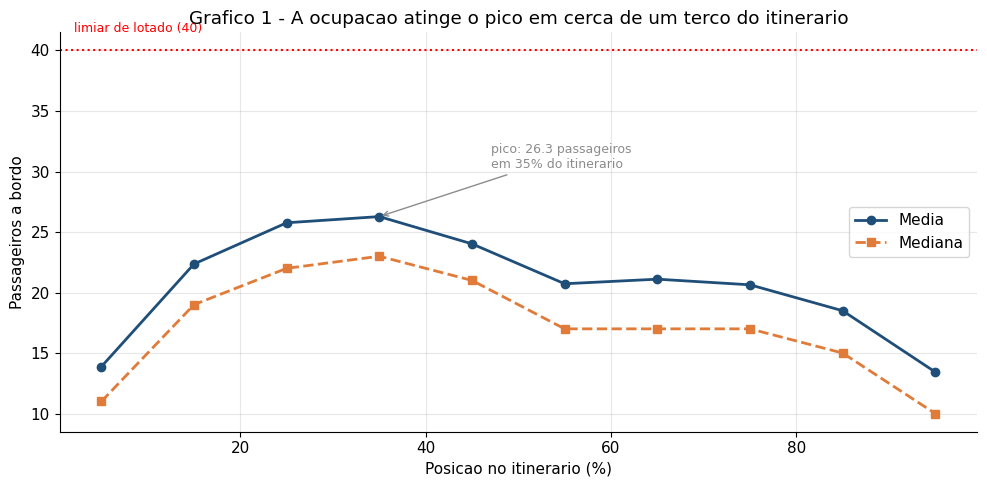

Pico de ocupacao: 26.3 passageiros em 35% do trajeto
Primeiro decil: 13.9 | Ultimo decil: 13.4


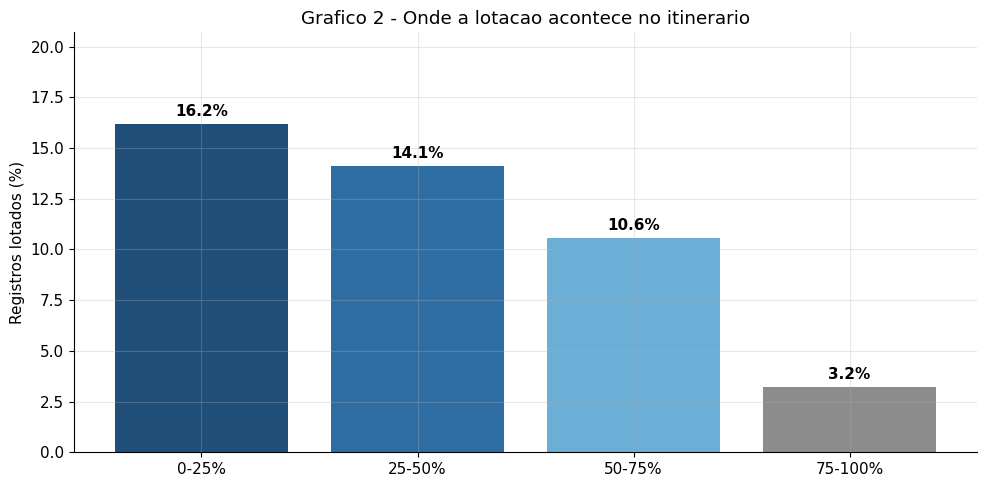

         size   pct
faixa              
0-25%    8703  16.2
25-50%   9123  14.1
50-75%   8748  10.6
75-100%  5899   3.2


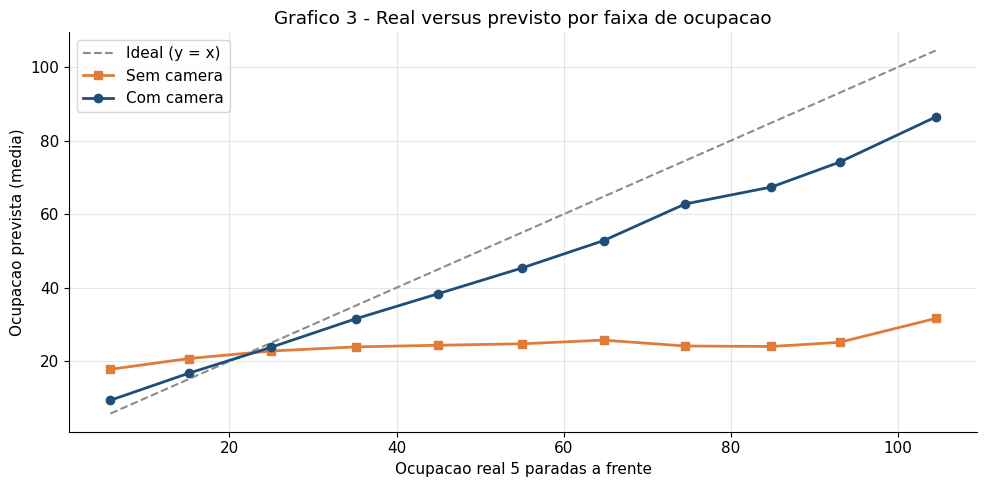

               real   sem   com     n
saldo_futuro                         
(0, 10]         5.8  17.8   9.4  8953
(10, 20]       15.1  20.7  16.7  8789
(20, 30]       25.0  22.8  23.8  5920
(30, 40]       35.1  23.9  31.5  3230
(40, 50]       45.0  24.3  38.3  1794
(50, 60]       55.0  24.7  45.3   913
(60, 70]       64.8  25.7  52.8   514
(70, 80]       74.5  24.1  62.8   159
(80, 90]       84.8  24.0  67.4   128
(90, 100]      93.0  25.1  74.1    27
(100, 110]    104.5  31.6  86.4    26


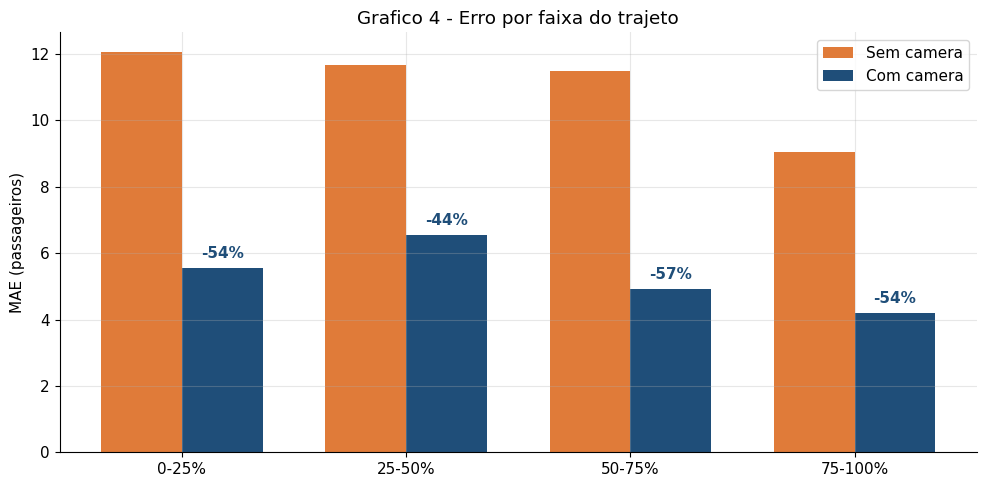

            n  MAE_sem  MAE_com  reducao
faixa                                   
0-25%    8703    12.05     5.55    53.92
25-50%   9123    11.67     6.54    43.92
50-75%   8748    11.50     4.91    57.29
75-100%  5899     9.05     4.19    53.74


In [6]:
# CELULA 6 - Visualizacoes (autocontida)
# Reconstroi base, split e modelos lineares para nao depender de celulas anteriores

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11,
})
AZUL, LARANJA, CINZA = "#1f4e79", "#e07b39", "#8c8c8c"
K, LIMIAR = 5, 40

# ---------- 1. reconstrucao da base ----------
d = df.sort_values(["viagem_id", "Sequencia do PED"]).reset_index(drop=True).copy()
d["saldo_futuro"] = d.groupby("viagem_id")["Saldo"].shift(-K)
d["total_pontos"] = d.groupby("viagem_id")["Sequencia do PED"].transform("max").replace(0, np.nan)
d["posicao_relativa"] = d["Sequencia do PED"] / d["total_pontos"]
d["posicao_relativa_2"] = d["posicao_relativa"] ** 2
d["paradas_restantes"] = d["total_pontos"] - d["Sequencia do PED"]

h = pd.to_datetime(d["Hora Viagem"].astype(str).str.strip(), format="%H:%M", errors="coerce")
d["hora"] = h.dt.hour
falta = d["hora"].isna()
if falta.any():
    alt = pd.to_numeric(d.loc[falta, "Hora Viagem"].astype(str)
                        .str.extract(r"(\d{1,2})")[0], errors="coerce")
    d.loc[falta, "hora"] = alt.where((alt >= 0) & (alt <= 23))

d["dia_semana_num"] = d["Data Pesquisa"].dt.dayofweek
d["ano"] = d["Data Pesquisa"].dt.year
d["ocup_atual"] = d["Saldo"]

base = d[d["saldo_futuro"].notna()].copy()
base["lotado_futuro"] = (base["saldo_futuro"] >= LIMIAR).astype(int)

top = base["Linha/SubLinha"].value_counts().head(10).index
base["linha_cat"] = np.where(base["Linha/SubLinha"].isin(top), base["Linha/SubLinha"], "OUTRAS")
dum = pd.get_dummies(base["linha_cat"], prefix="linha", drop_first=True).astype(int)
dum.index = base.index
base = pd.concat([base, dum], axis=1)
cols_linha = list(dum.columns)

FEAT_SEM = ["posicao_relativa", "posicao_relativa_2", "paradas_restantes",
            "hora", "dia_semana_num", "ano"] + cols_linha
FEAT_COM = FEAT_SEM + ["ocup_atual"]

# ---------- 2. split e modelos lineares ----------
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
idx_tr, idx_te = next(gss.split(base, groups=base["viagem_id"]))
treino, teste = base.iloc[idx_tr].copy(), base.iloc[idx_te].copy()

for cj in (treino, teste):
    cj["faixa"] = pd.cut(cj["posicao_relativa"], [0, .25, .5, .75, 1.01],
                         labels=["0-25%", "25-50%", "50-75%", "75-100%"],
                         include_lowest=True)

def treinar(feats):
    p = Pipeline([("imp", SimpleImputer(strategy="median")),
                  ("sc", StandardScaler()),
                  ("lr", LinearRegression())])
    p.fit(treino[feats].replace([np.inf, -np.inf], np.nan), treino["saldo_futuro"])
    return np.clip(p.predict(teste[feats].replace([np.inf, -np.inf], np.nan)), 0, 110)

teste["pred_sem"] = treinar(FEAT_SEM)
teste["pred_com"] = treinar(FEAT_COM)
print("Modelos treinados | MAE sem:", round(mean_absolute_error(teste["saldo_futuro"], teste["pred_sem"]), 3),
      "| MAE com:", round(mean_absolute_error(teste["saldo_futuro"], teste["pred_com"]), 3))

# ---------- GRAFICO 1: perfil de ocupacao ao longo do itinerario ----------
base["decil"] = pd.qcut(base["posicao_relativa"], 10, labels=False, duplicates="drop")
curva = base.groupby("decil")["Saldo"].agg(["mean", "median"])
curva["pos"] = (curva.index + 0.5) / len(curva) * 100
pico = curva["mean"].idxmax()

fig, ax = plt.subplots()
ax.plot(curva["pos"], curva["mean"], "o-", color=AZUL, lw=2, label="Media")
ax.plot(curva["pos"], curva["median"], "s--", color=LARANJA, lw=2, label="Mediana")
ax.axhline(LIMIAR, color="red", ls=":", lw=1.5)
ax.text(2, LIMIAR + 1.5, f"limiar de lotado ({LIMIAR})", color="red", fontsize=9)
ax.annotate(f"pico: {curva.loc[pico,'mean']:.1f} passageiros\nem {curva.loc[pico,'pos']:.0f}% do itinerario",
            xy=(curva.loc[pico, "pos"], curva.loc[pico, "mean"]),
            xytext=(curva.loc[pico, "pos"] + 12, curva.loc[pico, "mean"] + 4),
            arrowprops=dict(arrowstyle="->", color=CINZA), fontsize=9, color=CINZA)
ax.set_xlabel("Posicao no itinerario (%)")
ax.set_ylabel("Passageiros a bordo")
ax.set_title("Grafico 1 - A ocupacao atinge o pico em cerca de um terco do itinerario")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Pico de ocupacao: {curva['mean'].max():.1f} passageiros em {curva.loc[pico,'pos']:.0f}% do trajeto")
print(f"Primeiro decil: {curva['mean'].iloc[0]:.1f} | Ultimo decil: {curva['mean'].iloc[-1]:.1f}")

# ---------- GRAFICO 2: prevalencia de lotacao por faixa ----------
prev = teste.groupby("faixa", observed=True)["lotado_futuro"].agg(["mean", "size"])
prev["pct"] = prev["mean"] * 100

fig, ax = plt.subplots()
barras = ax.bar(prev.index.astype(str), prev["pct"], color=[AZUL, "#2e6da4", "#6baed6", CINZA])
for b, v in zip(barras, prev["pct"]):
    ax.text(b.get_x() + b.get_width()/2, v + 0.4, f"{v:.1f}%", ha="center", fontweight="bold")
ax.set_ylabel("Registros lotados (%)")
ax.set_ylim(0, prev["pct"].max() * 1.28)
ax.set_title("Grafico 2 - Onde a lotacao acontece no itinerario")
plt.tight_layout()
plt.show()

print(prev[["size", "pct"]].round(1).to_string())

# ---------- GRAFICO 3: real versus previsto ----------
cortes = np.arange(0, 115, 10)
comp = teste.groupby(pd.cut(teste["saldo_futuro"], cortes), observed=True).agg(
    real=("saldo_futuro", "mean"), sem=("pred_sem", "mean"),
    com=("pred_com", "mean"), n=("saldo_futuro", "size"))

fig, ax = plt.subplots()
ax.plot(comp["real"], comp["real"], "--", color=CINZA, lw=1.5, label="Ideal (y = x)")
ax.plot(comp["real"], comp["sem"], "s-", color=LARANJA, lw=2, label="Sem camera")
ax.plot(comp["real"], comp["com"], "o-", color=AZUL, lw=2, label="Com camera")
ax.set_xlabel("Ocupacao real 5 paradas a frente")
ax.set_ylabel("Ocupacao prevista (media)")
ax.set_title("Grafico 3 - Real versus previsto por faixa de ocupacao")
ax.legend()
plt.tight_layout()
plt.show()

print(comp.round(1).to_string())

# ---------- GRAFICO 4: erro por faixa do trajeto ----------
rows = []
for nome, g in teste.groupby("faixa", observed=True):
    rows.append({"faixa": str(nome), "n": len(g),
                 "MAE_sem": mean_absolute_error(g["saldo_futuro"], g["pred_sem"]),
                 "MAE_com": mean_absolute_error(g["saldo_futuro"], g["pred_com"])})
erro = pd.DataFrame(rows).set_index("faixa")
erro["reducao"] = (1 - erro["MAE_com"] / erro["MAE_sem"]) * 100

fig, ax = plt.subplots()
x, w = np.arange(len(erro)), 0.36
ax.bar(x - w/2, erro["MAE_sem"], w, color=LARANJA, label="Sem camera")
b2 = ax.bar(x + w/2, erro["MAE_com"], w, color=AZUL, label="Com camera")
ax.set_xticks(x); ax.set_xticklabels(erro.index)
ax.set_ylabel("MAE (passageiros)")
ax.set_title("Grafico 4 - Erro por faixa do trajeto")
ax.legend()
for b, r in zip(b2, erro["reducao"]):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.3,
            f"-{r:.0f}%", ha="center", fontweight="bold", color=AZUL)
plt.tight_layout()
plt.show()

print(erro.round(2).to_string())

In [7]:
# CELULA 7 - Indicador de impacto ao nivel de viagem (autocontida)
# Reconstroi base, split, modelos lineares e logisticos

import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error

K, LIMIAR, THR = 5, 40, 0.50

# ---------- 1. base ----------
d = df.sort_values(["viagem_id", "Sequencia do PED"]).reset_index(drop=True).copy()
d["saldo_futuro"] = d.groupby("viagem_id")["Saldo"].shift(-K)
d["total_pontos"] = d.groupby("viagem_id")["Sequencia do PED"].transform("max").replace(0, np.nan)
d["posicao_relativa"] = d["Sequencia do PED"] / d["total_pontos"]
d["posicao_relativa_2"] = d["posicao_relativa"] ** 2
d["paradas_restantes"] = d["total_pontos"] - d["Sequencia do PED"]

h = pd.to_datetime(d["Hora Viagem"].astype(str).str.strip(), format="%H:%M", errors="coerce")
d["hora"] = h.dt.hour
falta = d["hora"].isna()
if falta.any():
    alt = pd.to_numeric(
        d.loc[falta, "Hora Viagem"].astype(str).str.extract(r"(\d{1,2})")[0],
        errors="coerce")
    d.loc[falta, "hora"] = alt.where((alt >= 0) & (alt <= 23))

d["dia_semana_num"] = d["Data Pesquisa"].dt.dayofweek
d["ano"] = d["Data Pesquisa"].dt.year
d["ocup_atual"] = d["Saldo"]

base = d[d["saldo_futuro"].notna()].copy()
base["lotado_futuro"] = (base["saldo_futuro"] >= LIMIAR).astype(int)

top = base["Linha/SubLinha"].value_counts().head(10).index
base["linha_cat"] = np.where(base["Linha/SubLinha"].isin(top),
                             base["Linha/SubLinha"], "OUTRAS")
dum = pd.get_dummies(base["linha_cat"], prefix="linha", drop_first=True).astype(int)
dum.index = base.index
base = pd.concat([base, dum], axis=1)
cols_linha = list(dum.columns)

FEAT_SEM = ["posicao_relativa", "posicao_relativa_2", "paradas_restantes",
            "hora", "dia_semana_num", "ano"] + cols_linha
FEAT_COM = FEAT_SEM + ["ocup_atual"]

# ---------- 2. split ----------
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
itr, ite = next(gss.split(base, groups=base["viagem_id"]))
treino, teste = base.iloc[itr].copy(), base.iloc[ite].copy()

for cj in (treino, teste):
    cj["faixa"] = pd.cut(cj["posicao_relativa"], [0, .25, .5, .75, 1.01],
                         labels=["0-25%", "25-50%", "50-75%", "75-100%"],
                         include_lowest=True)

# ---------- 3. modelos lineares ----------
def treinar_linear(feats):
    p = Pipeline([("imp", SimpleImputer(strategy="median")),
                  ("sc", StandardScaler()),
                  ("lr", LinearRegression())])
    p.fit(treino[feats].replace([np.inf, -np.inf], np.nan), treino["saldo_futuro"])
    return np.clip(p.predict(teste[feats].replace([np.inf, -np.inf], np.nan)), 0, 110)

teste["pred_sem"] = treinar_linear(FEAT_SEM)
teste["pred_com"] = treinar_linear(FEAT_COM)

# ---------- 4. modelos logisticos ----------
def treinar_logistica(feats):
    p = Pipeline([("imp", SimpleImputer(strategy="median")),
                  ("sc", StandardScaler()),
                  ("lg", LogisticRegression(max_iter=3000,
                                            class_weight="balanced",
                                            random_state=42))])
    p.fit(treino[feats].replace([np.inf, -np.inf], np.nan), treino["lotado_futuro"])
    return p.predict_proba(teste[feats].replace([np.inf, -np.inf], np.nan))[:, 1]

teste["prob_sem"] = treinar_logistica(FEAT_SEM)
teste["prob_com"] = treinar_logistica(FEAT_COM)

print("=== METRICAS DE REFERENCIA ===")
print("MAE sem camera:", round(mean_absolute_error(teste["saldo_futuro"], teste["pred_sem"]), 3))
print("MAE com camera:", round(mean_absolute_error(teste["saldo_futuro"], teste["pred_com"]), 3))
print("Registros no teste:", len(teste))

# ---------- 5. alertas por registro ----------
teste["alerta_com"] = (teste["prob_com"] >= THR).astype(int)
teste["acerto_com"] = ((teste["alerta_com"] == 1) & (teste["lotado_futuro"] == 1)).astype(int)
teste["alerta_sem"] = (teste["prob_sem"] >= THR).astype(int)
teste["acerto_sem"] = ((teste["alerta_sem"] == 1) & (teste["lotado_futuro"] == 1)).astype(int)

# ---------- 6. indicador ao nivel de viagem ----------
viagens = teste.groupby("viagem_id").agg(
    pico_futuro=("saldo_futuro", "max"),
    n_pontos=("saldo_futuro", "size"),
    alertas_com=("alerta_com", "sum"),
    acertos_com=("acerto_com", "sum"),
    alertas_sem=("alerta_sem", "sum"),
    acertos_sem=("acerto_sem", "sum"),
)
viagens["critica"] = viagens["pico_futuro"] >= LIMIAR

vc = viagens[viagens["critica"]]
vn = viagens[~viagens["critica"]]

print("\n=== VIAGENS NO CONJUNTO DE TESTE ===")
print("Total:", len(viagens))
print("Criticas:", int(viagens["critica"].sum()),
      f"({viagens['critica'].mean()*100:.1f}%)")
print("Nao criticas:", len(vn))

cob_com = (vc["acertos_com"] > 0).mean() * 100
cob_sem = (vc["acertos_sem"] > 0).mean() * 100

print("\n=== COBERTURA DE VIAGENS CRITICAS ===")
print(f"Com camera: {cob_com:.1f}%  ({(vc['acertos_com']>0).sum()} de {len(vc)})")
print(f"Sem camera: {cob_sem:.1f}%  ({(vc['acertos_sem']>0).sum()} de {len(vc)})")

fa_com = (vn["alertas_com"] > 0).mean() * 100
fa_sem = (vn["alertas_sem"] > 0).mean() * 100

print("\n=== ALARME FALSO EM VIAGENS NAO CRITICAS ===")
print(f"Com camera recebeu alerta: {fa_com:.1f}%")
print(f"Sem camera recebeu alerta: {fa_sem:.1f}%")

print("\n=== ALERTAS POR VIAGEM ===")
print(viagens[["alertas_com", "alertas_sem"]].describe().round(1).to_string())

# ---------- 7. prevalencia por linha ----------
por_linha = teste.groupby("Linha/SubLinha").agg(
    registros=("lotado_futuro", "size"),
    lotados=("lotado_futuro", "sum"),
    prevalencia=("lotado_futuro", "mean"))
por_linha["prevalencia"] = (por_linha["prevalencia"] * 100).round(1)
por_linha = por_linha[por_linha["registros"] >= 100]

print("\n=== TOP 15 LINHAS POR PREVALENCIA ===")
print(por_linha.sort_values("prevalencia", ascending=False).head(15).to_string())

print("\n=== 5 LINHAS COM MENOR PREVALENCIA ===")
print(por_linha.sort_values("prevalencia").head(5).to_string())

# ---------- 8. numeros para as recomendacoes ----------
prec_com = teste.loc[teste["alerta_com"] == 1, "lotado_futuro"].mean() * 100
prec_sem = teste.loc[teste["alerta_sem"] == 1, "lotado_futuro"].mean() * 100

print("\n=== NUMEROS PARA O TEXTO DAS RECOMENDACOES ===")
print(f"Reducao de MAE pela camera: "
      f"{(1 - mean_absolute_error(teste['saldo_futuro'], teste['pred_com']) / mean_absolute_error(teste['saldo_futuro'], teste['pred_sem']))*100:.1f}%")
print(f"Precisao dos alertas com camera: {prec_com:.1f}%")
print(f"Precisao dos alertas sem camera: {prec_sem:.1f}%")
print(f"Alertas falsos com camera: {100 - prec_com:.1f}%")
print(f"Alertas falsos sem camera: {100 - prec_sem:.1f}%")
print(f"Prevalencia 0-25%:  {teste.loc[teste['faixa']=='0-25%','lotado_futuro'].mean()*100:.1f}%")
print(f"Prevalencia 75-100%: {teste.loc[teste['faixa']=='75-100%','lotado_futuro'].mean()*100:.1f}%")
print(f"Linha com maior prevalencia: {por_linha['prevalencia'].max():.1f}%")
print(f"Linha com menor prevalencia: {por_linha['prevalencia'].min():.1f}%")
print(f"Linhas acima de 20% de prevalencia: {(por_linha['prevalencia'] >= 20).sum()}")

=== METRICAS DE REFERENCIA ===
MAE sem camera: 11.25
MAE com camera: 5.41
Registros no teste: 32473

=== VIAGENS NO CONJUNTO DE TESTE ===
Total: 632
Criticas: 232 (36.7%)
Nao criticas: 400

=== COBERTURA DE VIAGENS CRITICAS ===
Com camera: 93.1%  (216 de 232)
Sem camera: 72.0%  (167 de 232)

=== ALARME FALSO EM VIAGENS NAO CRITICAS ===
Com camera recebeu alerta: 26.8%
Sem camera recebeu alerta: 48.0%

=== ALERTAS POR VIAGEM ===
       alertas_com  alertas_sem
count        632.0        632.0
mean          10.7         22.6
std           14.5         25.6
min            0.0          0.0
25%            0.0          0.0
50%            2.5         14.0
75%           19.0         43.2
max           77.0        170.0

=== TOP 15 LINHAS POR PREVALENCIA ===
                registros  lotados  prevalencia
Linha/SubLinha                                 
1404B/01              340      146         42.9
2224A/05              118       46         39.0
2215B/01              228       81         35.5
2

## 8. Recomendações

**1. Não lançar o produto sem o sensor de contagem a bordo.**
O modelo sem câmera emite 81,3% de alertas falsos e cobre apenas 72,0% das viagens críticas. Ele prevê entre 17,8 e 31,6 passageiros para uma faixa real de 5,8 a 104,5 — praticamente não distingue ônibus vazio de ônibus lotado, porque responde "cerca de 24 passageiros" para qualquer situação. Com a câmera, a precisão sobe de 18,7% para 50,1%, os alertas falsos caem para 49,9% e a cobertura chega a 93,1%.
Impacto: o sistema passa de "avisa quase sempre e erra quatro em cinco" para "avisa metade das vezes e acerta metade", patamar em que o cidadão ainda confia no aviso.
Limitação: o ganho medido trata a leitura como exata. Sensores reais erram entre 5% e 10%, então o desempenho reportado é limite superior, não promessa.

**2. Priorizar a instalação nas 16 linhas com prevalência acima de 20%.**
A prevalência de lotação varia de 0,0% a 42,9% entre as linhas analisadas. A 1404B/01 lidera com 42,9%, seguida por 2224A/05 (39,0%) e 2215B/01 (35,5%). Na outra ponta, 101/01, 103/01, 1145/01, 107/01 e 1207C/01 não registraram nenhum ponto com lotação prevista. Dezesseis linhas concentram a maior parte dos casos críticos.
Impacto: cobrir as linhas prioritárias entrega a maior parte do benefício ao cidadão com uma fração do investimento de equipar a frota inteira.
Limitação: a seleção usa amostra de 2008 a 2018. A demanda por linha mudou em uma década e precisa ser reconfirmada com bilhetagem recente antes da compra.

**3. Concentrar o alerta no primeiro terço do itinerário.**
A ocupação a bordo atinge o pico de 26,3 passageiros em 35% do percurso e cai até 13,4 no fim. A prevalência de lotação cinco paradas à frente é de 16,2% no primeiro quarto do trajeto, 14,1% no segundo, 10,6% no terceiro e 3,2% no último: os dois primeiros quartos concentram 78% dos casos críticos.
Impacto: o valor do sistema está em avisar quando o veículo ainda está enchendo, no trecho em que o cidadão tem alternativa. Alertas no quarto final podem ser desativados para reduzir ruído sem perda relevante.
Limitação: o pico em um terço do percurso é a média da amostra. Linhas troncais com embarque concentrado na origem podem apresentar curva distinta e exigir calibração própria.

**4. Medir o sucesso pela cobertura de viagens críticas, não pela acurácia do modelo.**
Adotamos como indicador a proporção de viagens com lotação prevista em que o sistema emitiu alerta correto com pelo menos 5 paradas de antecedência. No conjunto de teste, o valor é de 93,1% com câmera e 72,0% sem — 216 e 167 das 232 viagens críticas. A meta de 80% foi superada.
Impacto: mede o que muda na vida do passageiro, que é decidir a tempo, em vez de desempenho interno do modelo.
Limitação: o indicador depende do horizonte de 5 paradas. Alterar o horizonte muda o número, então ele só é comparável entre versões que usem o mesmo horizonte.

**5. Tratar a redução de ruído como requisito de produto, não como detalhe técnico.**
A mediana de alertas por viagem cai de 14,0 no modelo sem câmera para 2,5 com câmera, redução de 82%. Em viagens que nunca ficaram lotadas, o aviso indevido cai de 48,0% para 26,8% dos casos.
Impacto: um aplicativo que notifica 14 vezes por trajeto é desinstalado; com 2,5, o alerta preserva credibilidade.
Limitação: 26,8% de alarme falso em viagens tranquilas continua sendo custo real. Recomenda-se avaliar um segundo limiar de confiança para envio de notificação push.

**6. Começar por Belo Horizonte e tratar a expansão como projeto separado.**
A base é da capital mineira, com 3.156 viagens e 157 linhas pesquisadas entre 2008 e 2018. A lógica de acumulação de ocupação é genérica, mas o limiar de 40 passageiros reflete a frota local.
Impacto: entrega funcionando em um território conhecido, com dado público verificável, antes de prometer escala.
Limitação: em outra cidade, tanto a capacidade média dos veículos quanto a distribuição de demanda mudam, e o modelo exige re-treino com dado local.

## 9. Limitações do estudo

**A base cobre dez anos com amostragem irregular.** São 160 datas entre novembro de 2008 e março de 2018, sem continuidade mensal: fevereiro de 2009 tem 16.427 registros e julho do mesmo ano tem 405, com meses sem nenhum. Por isso a divisão entre treino e teste foi feita por viagem, e não por data. Agrupar por `viagem_id` garante que nenhuma viagem apareça nos dois conjuntos, enquanto uma divisão temporal fingiria uma série que não existe. O resultado é 2.524 viagens no treino e 632 no teste, sem interseção.

**6,8% dos registros têm inconsistência interna.** Em 12.346 linhas, o saldo informado difere do acumulado de embarques menos desembarques, com diferença de até 89 passageiros. Optamos por não recalcular, porque corrigir inventaria dado. O efeito é ruído no alvo, que reduz o teto de desempenho de todos os modelos igualmente e não favorece nenhum.

**A direção do itinerário é desbalanceada.** São 155.884 registros em `Pc1->Pc2` contra 21.387 em `Pc2->Pc1`. O modelo aprende melhor um sentido que o outro, e a avaliação separada por sentido não foi realizada.

**O modelo perde precisão nos extremos.** Acima de 90 passageiros há apenas 53 registros no conjunto de teste, e a previsão média cai para 86,4 contra 93,0 e 104,5 reais. A cauda superior está sub-representada e o erro nessa faixa é maior que a média reportada de 5,41.

**O limiar de 40 passageiros é uma convenção de produto.** Corresponde à ocupação de todos os assentos de um veículo convencional, mas não mede os assentos reais da frota pesquisada. Mudar o limiar altera a prevalência de 12,1% e todas as métricas de classificação — em 30 passageiros a prevalência seria 23,2%, em 50 seria 6,1%.

**O desempenho é limite superior, não expectativa.** A leitura de ocupação entra no modelo sem erro de medição. Com erro de sensor entre 5% e 10%, o ganho observado de 51,9% no MAE seria menor.

**A análise não incorpora tempo real de viagem.** A base traz horário programado de início, não o horário efetivamente realizado. Atrasos, que afetam a ocupação, não entram como variável, e a chuva e a temperatura que constavam do projeto original não existem nesta base.

**O alarme falso remanescente é custo assumido.** Em 26,8% das viagens que não ficaram lotadas, o modelo com câmera ainda emite alerta. É o preço de priorizar recall: preferimos avisar demais a deixar o cidadão embarcar em um ônibus cheio.

## 10. Conclusão

A pergunta do projeto era se é possível avisar o cidadão sobre a lotação de um ônibus antes de ele decidir embarcar, usando dado real de contagem de passageiros. A resposta é sim, com duas condições.

A primeira é que exista leitura a bordo. Sem ela, o modelo de ocupação explica apenas 17,2% da variação e emite 81,3% de alertas falsos — na prática, não informa nada. Com ela, o R² sobe para 0,745, a cobertura de viagens críticas chega a 93,1% e o erro médio cai de 11,25 para 5,41 passageiros.

A segunda é que o alerta chegue no momento certo. A lotação se concentra no primeiro terço do itinerário, com 16,2% de prevalência no primeiro quarto e 3,2% no último. Avisar no fim do percurso é informação sem utilidade.

O trabalho entrega ainda um critério de priorização: 16 das 157 linhas concentram a maior parte dos casos críticos, com prevalência acima de 20%, chegando a 42,9% na 1404B/01. Para uma implantação real, é por ali que se começa.